# Laboratory Work #2 — REINFORCE & DQN on CartPole

**Environment:** `CartPole-v1` (Gymnasium). Observation = 4 numbers (cart position, cart velocity, pole angle, pole angular velocity), 2 actions (push left / push right). Reward is +1 for every step the pole is still up, max 500 per episode.

In this lab I implement two algorithms:
- **Part A — REINFORCE** (policy gradient, Monte Carlo)
- **Part B — DQN** (Deep Q-Network, TD learning with replay memory and target network)

and then I compare them on 3 random seeds.

## 0. Setup and library versions

In [1]:
# pip install gymnasium torch numpy matplotlib
import random
import sys
from collections import deque

import gymnasium as gym
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim

print("Python     :", sys.version.split()[0])
print("PyTorch    :", torch.__version__)
print("Gymnasium  :", gym.__version__)
print("NumPy      :", np.__version__)
print("Matplotlib :", matplotlib.__version__)

SEEDS = [0, 1, 2]  # seeds I use for all experiments


def set_seed(seed):
    # fix all random generators so the results can be repeated
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


def rolling_mean(x, window=20):
    # simple moving average for nicer plots
    out = []
    for i in range(len(x)):
        start = max(0, i - window + 1)
        out.append(np.mean(x[start:i + 1]))
    return out

Python     : 3.14.7
PyTorch    : 2.15.0
Gymnasium  : 1.4.0
NumPy      : 2.5.4
Matplotlib : 3.11.2


In [2]:
# quick look at the environment
env = gym.make("CartPole-v1")
obs, info = env.reset(seed=0)
print("observation space:", env.observation_space)
print("action space     :", env.action_space)
print("first observation:", obs)
env.close()

observation space: Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)
action space     : Discrete(2)
first observation: [ 0.01369617 -0.02302133 -0.04590265 -0.04834723]


# Part A — REINFORCE

## A.1 Policy network

The policy network takes the 4-dimensional observation and outputs **probabilities** for the 2 actions (softmax at the end, so they sum to 1). Then we sample the action from these probabilities.

In [3]:
class PolicyNet(nn.Module):
    def __init__(self, obs_dim=4, n_actions=2, hidden=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(obs_dim, hidden),
            nn.ReLU(),
            nn.Linear(hidden, n_actions),
            nn.Softmax(dim=-1),
        )

    def forward(self, x):
        return self.net(x)


# check: output should be 2 probabilities that sum to 1
test_policy = PolicyNet()
p = test_policy(torch.zeros(4))
print("probabilities:", p.detach().numpy(), " sum =", p.sum().item())

probabilities: [0.45010024 0.5498998 ]  sum = 1.0


## A.2 Discounted returns

For every time step $t$ the return is $G_t = r_t + \gamma r_{t+1} + \gamma^2 r_{t+2} + \dots$

It is easiest to compute it **backwards** like in Lab 1: $G_t = r_t + \gamma G_{t+1}$, starting from $G = 0$ after the last step.

In [4]:
def discounted_returns(rewards, gamma):
    # TODO: compute G_t for every step of the episode
    returns = []
    G = 0.0
    for r in reversed(rewards):
        G = r + gamma * G
        returns.append(G)
    returns.reverse()  # because I went from the end to the start
    return torch.tensor(returns, dtype=torch.float32)

In [5]:
# unit test
out = discounted_returns([1.0, 1.0, 1.0], gamma=0.5)
print(out)
# by hand: G2 = 1, G1 = 1 + 0.5*1 = 1.5, G0 = 1 + 0.5*1.5 = 1.75
assert torch.allclose(out, torch.tensor([1.75, 1.5, 1.0])), "discounted_returns is wrong"

# one more test with gamma = 0.99 and different rewards
out2 = discounted_returns([0.0, 0.0, 10.0], gamma=0.99)
assert torch.allclose(out2, torch.tensor([10 * 0.99 ** 2, 10 * 0.99, 10.0]))
print("discounted_returns tests passed!")

tensor([1.7500, 1.5000, 1.0000])
discounted_returns tests passed!


## A.3 Policy loss

The REINFORCE gradient is $\nabla J(\theta) = \mathbb{E}\left[\sum_t G_t \nabla \log \pi_\theta(a_t|s_t)\right]$.

We want to **maximize** $J$, but the PyTorch optimizer **minimizes** the loss, so I put a minus sign:
$$L(\theta) = -\sum_t \log \pi_\theta(a_t|s_t)\, G_t$$

In [6]:
def policy_loss(log_probs, returns):
    # TODO: REINFORCE loss (minus because optimizer minimizes)
    return -(log_probs * returns).sum()

In [7]:
# unit test
lp = torch.tensor([-0.5, -1.0])
G = torch.tensor([2.0, 1.0])
loss = policy_loss(lp, G)
print("loss =", loss.item())
# by hand: -((-0.5)*2 + (-1.0)*1) = -(-1 - 1) = 2
assert abs(loss.item() - 2.0) < 1e-6

# check that the gradient goes to the right direction:
# if the return is positive, minimizing the loss should increase log prob
x = torch.tensor([-1.0], requires_grad=True)
policy_loss(x, torch.tensor([5.0])).backward()
assert x.grad.item() < 0  # negative gradient -> gradient descent increases x
print("policy_loss tests passed!")

loss = 2.0
policy_loss tests passed!


## A.4 Training

Hyperparameters from the task: up to **250 episodes**, $\gamma = 0.99$, Adam with learning rate **0.01**.

One small thing I added: I normalize the returns inside every episode (subtract mean, divide by std). I read that this is a common trick that makes training much more stable (it works like a simple baseline). Without it the returns for CartPole are all positive and big (like 50–100), so the gradients are very noisy.

In [8]:
def train_reinforce(seed, n_episodes=250, gamma=0.99, lr=0.01, normalize=True):
    set_seed(seed)
    env = gym.make("CartPole-v1")
    policy = PolicyNet()
    optimizer = optim.Adam(policy.parameters(), lr=lr)

    episode_returns = []
    for ep in range(n_episodes):
        # use a different env seed for every episode, but based on the main seed
        obs, _ = env.reset(seed=seed * 10_000 + ep)
        log_probs = []
        rewards = []
        done = False

        # 1) play one full episode with the current policy
        while not done:
            obs_t = torch.tensor(obs, dtype=torch.float32)
            probs = policy(obs_t)
            dist = torch.distributions.Categorical(probs)
            action = dist.sample()
            log_probs.append(dist.log_prob(action))

            obs, reward, terminated, truncated, _ = env.step(action.item())
            rewards.append(reward)
            done = terminated or truncated

        # 2) compute returns for every step
        returns = discounted_returns(rewards, gamma)
        if normalize and len(returns) > 1:
            returns = (returns - returns.mean()) / (returns.std() + 1e-8)

        # 3) one gradient step
        loss = policy_loss(torch.stack(log_probs), returns)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        episode_returns.append(sum(rewards))
        if (ep + 1) % 50 == 0:
            print(f"seed {seed} | episode {ep + 1:3d} | return {sum(rewards):6.1f} "
                  f"| mean last 20 = {np.mean(episode_returns[-20:]):6.1f}")

    env.close()
    return episode_returns

In [9]:
reinforce_results = {}
for seed in SEEDS:
    reinforce_results[seed] = train_reinforce(seed)

seed 0 | episode  50 | return   13.0 | mean last 20 =   13.3
seed 0 | episode 100 | return   30.0 | mean last 20 =   25.9


seed 0 | episode 150 | return   71.0 | mean last 20 =   64.9


seed 0 | episode 200 | return   68.0 | mean last 20 =   97.8


seed 0 | episode 250 | return   69.0 | mean last 20 =   92.0
seed 1 | episode  50 | return   20.0 | mean last 20 =   14.7


seed 1 | episode 100 | return  153.0 | mean last 20 =   64.3


seed 1 | episode 150 | return  500.0 | mean last 20 =  293.9


... (3 outputs left out)

seed 2 | episode 100 | return  408.0 | mean last 20 =  182.5


seed 2 | episode 150 | return  423.0 | mean last 20 =  444.1


seed 2 | episode 200 | return  500.0 | mean last 20 =  500.0


seed 2 | episode 250 | return  500.0 | mean last 20 =  492.5


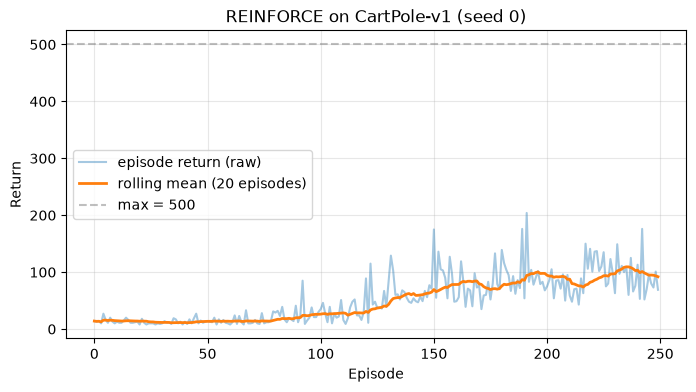

In [10]:
# plot for the first seed: raw returns and rolling average
r = reinforce_results[SEEDS[0]]
plt.figure(figsize=(8, 4))
plt.plot(r, alpha=0.4, label="episode return (raw)")
plt.plot(rolling_mean(r, 20), linewidth=2, label="rolling mean (20 episodes)")
plt.axhline(500, color="gray", linestyle="--", alpha=0.5, label="max = 500")
plt.xlabel("Episode")
plt.ylabel("Return")
plt.title(f"REINFORCE on CartPole-v1 (seed {SEEDS[0]})")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

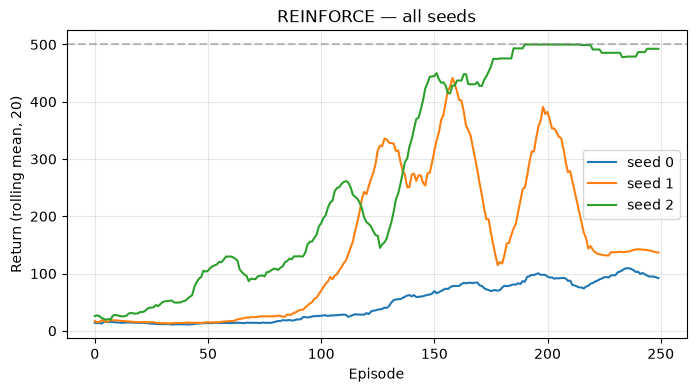

In [11]:
# all seeds together (only rolling mean so the plot is readable)
plt.figure(figsize=(8, 4))
for seed in SEEDS:
    plt.plot(rolling_mean(reinforce_results[seed], 20), label=f"seed {seed}")
plt.axhline(500, color="gray", linestyle="--", alpha=0.5)
plt.xlabel("Episode")
plt.ylabel("Return (rolling mean, 20)")
plt.title("REINFORCE — all seeds")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## A.5 Explanation (Part A)

**Why is the policy stochastic?** The network gives probabilities and we *sample* the action, so the agent automatically explores: even an action with low probability is sometimes tried. Also the policy gradient formula needs $\log \pi(a|s)$, and that only makes sense when the policy is a probability distribution that changes smoothly with the weights. A deterministic argmax policy would have no gradient.

**Why does the update need the episode return?** REINFORCE is a Monte Carlo method: it doesn't have a value function to estimate how good an action was, so it uses the real return $G_t$ that happened after the action. That's why we have to wait until the episode is finished. Actions followed by high returns get their probability pushed up, and actions followed by low returns get pushed down. Because $G_t$ depends on everything that happened later in the episode, the estimate has high variance, which is why my curves are so noisy.

# Part B — DQN

## B.1 Q-network

This network is different from the policy network: it outputs **2 Q-values** $Q(s, \text{left})$ and $Q(s, \text{right})$, not probabilities. There is no softmax and the numbers can be any real values. To act greedily we take the argmax.

In [12]:
class QNet(nn.Module):
    def __init__(self, obs_dim=4, n_actions=2, hidden=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(obs_dim, hidden),
            nn.ReLU(),
            nn.Linear(hidden, hidden),
            nn.ReLU(),
            nn.Linear(hidden, n_actions),  # no softmax here!
        )

    def forward(self, x):
        return self.net(x)


test_q = QNet()
print("Q-values:", test_q(torch.zeros(4)).detach().numpy())

Q-values: [-0.10872509 -0.01306552]


## B.2 DQN targets

$$y = r + \gamma \,(1 - \text{done})\, \max_{a'} Q_{\text{target}}(s', a')$$

If the transition is terminal (done = 1), there is no next state, so the target is just the reward $r$.

Note: in CartPole an episode can also end because of the **time limit** (truncated at 500 steps). That is not a real terminal state, so I only use `terminated` as `done` for the target, not `truncated`.

In [13]:
def dqn_targets(rewards, next_q_max, dones, gamma):
    # TODO: TD target with terminal masking
    return rewards + gamma * (1.0 - dones) * next_q_max

In [14]:
# unit test
rewards = torch.tensor([1.0, 1.0])
next_q_max = torch.tensor([10.0, 10.0])
dones = torch.tensor([0.0, 1.0])
y = dqn_targets(rewards, next_q_max, dones, gamma=0.9)
print("targets:", y)
# not terminal: 1 + 0.9*10 = 10, terminal: just 1
assert torch.allclose(y, torch.tensor([10.0, 1.0])), "dqn_targets is wrong"
print("dqn_targets tests passed! (terminal masking works)")

targets: tensor([10.,  1.])
dqn_targets tests passed! (terminal masking works)


## B.3 Replay memory and the mini-batch update

The replay memory stores transitions $(s, a, r, s', \text{done})$. For the update I take a random mini-batch, then:
1. gather $Q(s, a)$ for the action that was actually taken (with `gather`),
2. compute the target with the **target network** (no gradients),
3. minimize MSE between them.

In [15]:
class ReplayMemory:
    def __init__(self, capacity):
        self.buffer = deque(maxlen=capacity)  # old transitions are removed automatically

    def push(self, s, a, r, s_next, done):
        self.buffer.append((s, a, r, s_next, done))

    def sample(self, batch_size):
        batch = random.sample(self.buffer, batch_size)
        s, a, r, s_next, done = zip(*batch)
        return (torch.tensor(np.array(s), dtype=torch.float32),
                torch.tensor(a, dtype=torch.int64),
                torch.tensor(r, dtype=torch.float32),
                torch.tensor(np.array(s_next), dtype=torch.float32),
                torch.tensor(done, dtype=torch.float32))

    def __len__(self):
        return len(self.buffer)


def dqn_update(q_net, target_net, optimizer, memory, batch_size, gamma):
    s, a, r, s_next, done = memory.sample(batch_size)

    # TODO 1: Q(s, a) for the actions we took
    q_sa = q_net(s).gather(1, a.unsqueeze(1)).squeeze(1)

    # TODO 2: target with the target network (no gradient!)
    with torch.no_grad():
        next_q_max = target_net(s_next).max(dim=1).values
        y = dqn_targets(r, next_q_max, done, gamma)

    # TODO 3: MSE loss and gradient step
    loss = nn.functional.mse_loss(q_sa, y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    return loss.item()

In [16]:
# small test of the update: the shapes must be right and the loss must go down
set_seed(0)
q_test, t_test = QNet(), QNet()
t_test.load_state_dict(q_test.state_dict())
opt_test = optim.Adam(q_test.parameters(), lr=1e-3)
mem_test = ReplayMemory(100)
for i in range(64):
    mem_test.push(np.random.randn(4), i % 2, 1.0, np.random.randn(4), float(i % 10 == 0))

s, a, r, s2, d = mem_test.sample(8)
print("q_sa shape:", q_test(s).gather(1, a.unsqueeze(1)).squeeze(1).shape)  # should be [8]

losses = [dqn_update(q_test, t_test, opt_test, mem_test, 32, 0.99) for _ in range(200)]
print(f"loss at the start: {losses[0]:.3f}, after 200 updates: {losses[-1]:.4f}")
assert losses[-1] < losses[0]
print("dqn_update test passed!")

q_sa shape: torch.Size([8])


loss at the start: 1.065, after 200 updates: 0.0044
dqn_update test passed!


## B.4 Training

- up to **350 episodes**, $\gamma = 0.99$, Adam lr = 0.0005
- epsilon-greedy: $\varepsilon$ goes linearly from 1.0 to 0.05 during the first 10,000 steps
- replay memory with 50,000 transitions, batch size 64, training starts after 1,000 transitions
- target network copied every 500 steps

In [17]:
def select_action(q_net, obs, epsilon, n_actions=2):
    if random.random() < epsilon:
        return random.randrange(n_actions)  # explore
    with torch.no_grad():
        q = q_net(torch.tensor(obs, dtype=torch.float32))
    return int(q.argmax().item())  # exploit


def train_dqn(seed, n_episodes=350, gamma=0.99, lr=5e-4, batch_size=64,
              memory_size=50_000, start_learning=1_000, target_update=500,
              eps_start=1.0, eps_end=0.05, eps_decay_steps=10_000):
    set_seed(seed)
    env = gym.make("CartPole-v1")
    env.action_space.seed(seed)

    q_net = QNet()
    target_net = QNet()
    target_net.load_state_dict(q_net.state_dict())  # start with the same weights
    optimizer = optim.Adam(q_net.parameters(), lr=lr)
    memory = ReplayMemory(memory_size)

    total_steps = 0
    episode_returns = []
    for ep in range(n_episodes):
        obs, _ = env.reset(seed=seed * 10_000 + ep)
        ep_return = 0.0
        done = False
        while not done:
            # linear epsilon decay
            frac = min(1.0, total_steps / eps_decay_steps)
            epsilon = eps_start + frac * (eps_end - eps_start)

            action = select_action(q_net, obs, epsilon)
            next_obs, reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated

            # store only "terminated" as done (time limit is not a real terminal state)
            memory.push(obs, action, reward, next_obs, float(terminated))
            obs = next_obs
            ep_return += reward
            total_steps += 1

            if len(memory) >= start_learning:
                dqn_update(q_net, target_net, optimizer, memory, batch_size, gamma)

            # copy weights to the target network from time to time
            if total_steps % target_update == 0:
                target_net.load_state_dict(q_net.state_dict())

        episode_returns.append(ep_return)
        if (ep + 1) % 50 == 0:
            print(f"seed {seed} | episode {ep + 1:3d} | return {ep_return:6.1f} "
                  f"| mean last 20 = {np.mean(episode_returns[-20:]):6.1f} | eps = {epsilon:.2f}")

    env.close()
    return episode_returns

In [18]:
dqn_results = {}
for seed in SEEDS:
    dqn_results[seed] = train_dqn(seed)

seed 0 | episode  50 | return   12.0 | mean last 20 =   26.4 | eps = 0.88


seed 0 | episode 100 | return   19.0 | mean last 20 =   20.7 | eps = 0.78


seed 0 | episode 150 | return   40.0 | mean last 20 =   42.8 | eps = 0.61


seed 0 | episode 200 | return  329.0 | mean last 20 =  203.1 | eps = 0.05


seed 0 | episode 250 | return  145.0 | mean last 20 =  206.7 | eps = 0.05


seed 0 | episode 300 | return  155.0 | mean last 20 =  155.6 | eps = 0.05


... (9 outputs left out)

seed 2 | episode 200 | return  194.0 | mean last 20 =  184.8 | eps = 0.11


seed 2 | episode 250 | return  121.0 | mean last 20 =  150.0 | eps = 0.05


seed 2 | episode 300 | return  110.0 | mean last 20 =  138.8 | eps = 0.05


seed 2 | episode 350 | return  149.0 | mean last 20 =  128.8 | eps = 0.05


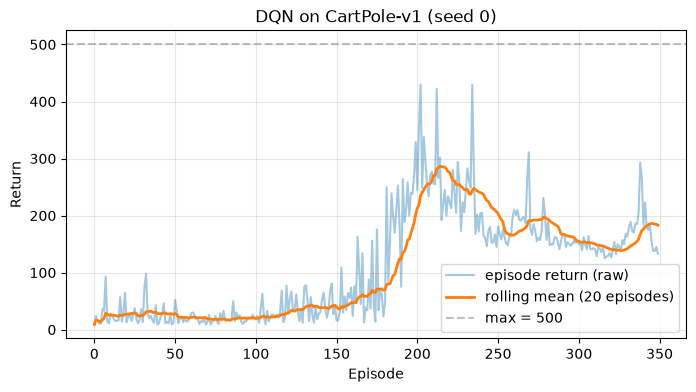

In [19]:
r = dqn_results[SEEDS[0]]
plt.figure(figsize=(8, 4))
plt.plot(r, alpha=0.4, label="episode return (raw)")
plt.plot(rolling_mean(r, 20), linewidth=2, label="rolling mean (20 episodes)")
plt.axhline(500, color="gray", linestyle="--", alpha=0.5, label="max = 500")
plt.xlabel("Episode")
plt.ylabel("Return")
plt.title(f"DQN on CartPole-v1 (seed {SEEDS[0]})")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

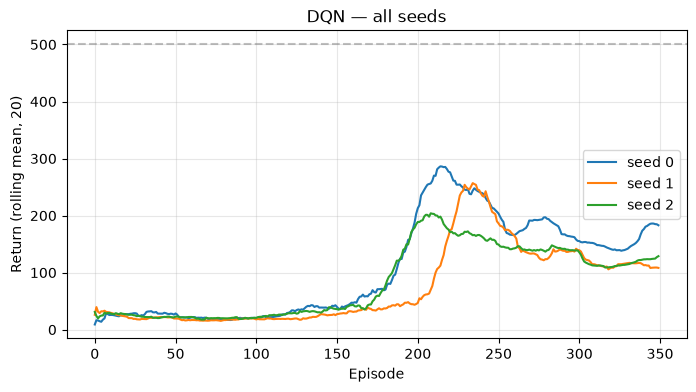

In [20]:
plt.figure(figsize=(8, 4))
for seed in SEEDS:
    plt.plot(rolling_mean(dqn_results[seed], 20), label=f"seed {seed}")
plt.axhline(500, color="gray", linestyle="--", alpha=0.5)
plt.xlabel("Episode")
plt.ylabel("Return (rolling mean, 20)")
plt.title("DQN — all seeds")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## B.5 Explanation (Part B)

**Why do replay memory and target networks help?** Transitions that come one after another in an episode are very similar to each other (correlated), and neural networks train badly on correlated data. Sampling random mini-batches from the replay memory breaks this correlation, and each transition can be used many times, so DQN is more sample-efficient. The target network is a frozen copy of the Q-network: without it, the target $y$ would change every time we update the weights, so we would be "chasing a moving target" and training could oscillate or diverge.

**How is DQN different from REINFORCE?** REINFORCE learns the policy directly and updates it with the full Monte Carlo return after each episode (on-policy, the data is thrown away after one update). DQN learns Q-values and builds the policy from them with argmax / epsilon-greedy. It updates after every step using a bootstrapped TD target (one reward + its own estimate of the next state), and it is off-policy, so it can learn from old data in the replay memory.

# 5. Comparison

Mean return over the **final 20 episodes** for every seed, and then the mean (± std) across seeds.

In [21]:
def final_mean(returns, last=20):
    return float(np.mean(returns[-last:]))


print(f"{'Seed':>6} | {'REINFORCE':>10} | {'DQN':>10}")
print("-" * 33)
rf_scores, dqn_scores = [], []
for seed in SEEDS:
    a = final_mean(reinforce_results[seed])
    b = final_mean(dqn_results[seed])
    rf_scores.append(a)
    dqn_scores.append(b)
    print(f"{seed:>6} | {a:>10.1f} | {b:>10.1f}")
print("-" * 33)
print(f"{'mean':>6} | {np.mean(rf_scores):>10.1f} | {np.mean(dqn_scores):>10.1f}")
print(f"{'std':>6} | {np.std(rf_scores):>10.1f} | {np.std(dqn_scores):>10.1f}")

  Seed |  REINFORCE |        DQN
---------------------------------
     0 |       92.0 |      183.0
     1 |      136.9 |      108.2
     2 |      492.5 |      128.8
---------------------------------
  mean |      240.5 |      140.0
   std |      179.2 |       31.5


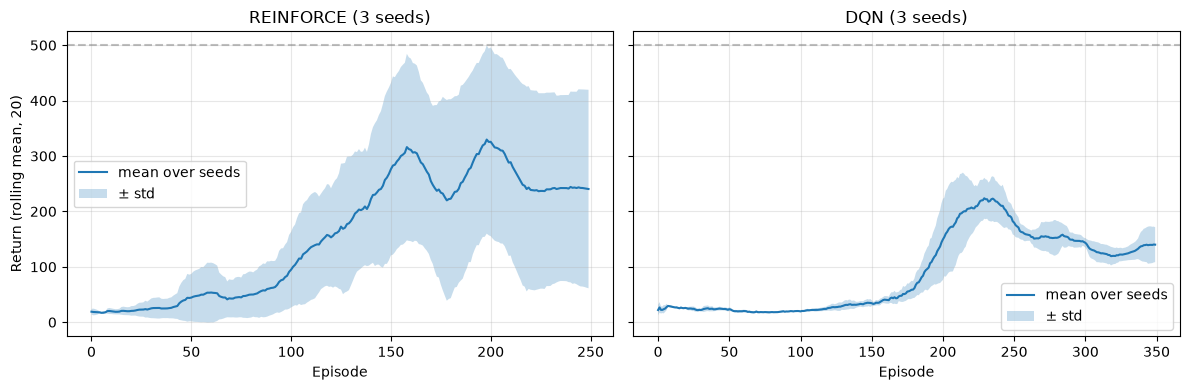

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, results, name in [(axes[0], reinforce_results, "REINFORCE"), (axes[1], dqn_results, "DQN")]:
    curves = np.array([rolling_mean(results[s], 20) for s in SEEDS])
    mean, std = curves.mean(axis=0), curves.std(axis=0)
    x = np.arange(len(mean))
    ax.plot(x, mean, label="mean over seeds")
    ax.fill_between(x, mean - std, mean + std, alpha=0.25, label="± std")
    ax.axhline(500, color="gray", linestyle="--", alpha=0.5)
    ax.set_title(f"{name} ({len(SEEDS)} seeds)")
    ax.set_xlabel("Episode")
    ax.grid(alpha=0.3)
    ax.legend()
axes[0].set_ylabel("Return (rolling mean, 20)")
plt.tight_layout()
plt.show()

## Reflection

**My results (mean return of the last 20 episodes):**

| Seed | REINFORCE (250 ep.) | DQN (350 ep.) |
|---|---|---|
| 0 | 92.0 | 183.0 |
| 1 | 136.9 | 108.2 |
| 2 | 492.5 | 128.8 |
| **mean ± std** | **240.5 ± 179.2** | **140.0 ± 31.5** |

**What I see:** Both methods learn something (random play gives ~20). REINFORCE has a higher mean, but it is mostly because of seed 2 that reached 500. The other two seeds are lower than DQN, and seed 1 even reached ~380 and then collapsed back to ~137. So REINFORCE has very high variance between seeds. DQN was slow at the start (epsilon is high for the first ~10,000 steps, so it is basically random), then jumped to ~200 around episode 200–230 and then went down a bit to ~110–180. But the 3 seeds are much closer to each other. With only 3 seeds and such a big std I can't say that one method is better in general. The results also depend a lot on hyperparameters I didn't tune (learning rate, epsilon schedule, target update period).

**(a) Which model outputs action probabilities?** The REINFORCE policy network (softmax output). The DQN network outputs Q-values, not probabilities.

**(b) Which method uses complete returns?** REINFORCE. It waits until the episode ends and uses the full discounted return $G_t$ (Monte Carlo).

**(c) Which method bootstraps?** DQN. Its target $r + \gamma \max_{a'} Q_{\text{target}}(s', a')$ uses its own estimate of the next state's value instead of the real future rewards.

**(d) Which uses replay?** DQN (replay memory with random mini-batches). REINFORCE is on-policy and uses each episode only once.

**(e) What is the effect of a terminal transition on the DQN target?** When `done = 1` the term $\gamma (1 - \text{done}) \max Q$ becomes 0, so the target is just the reward $y = r$. This makes sense because there are no future rewards after the episode ends. If we forget this masking, the network would think the pole falling still has future value. (In my code, the time-limit truncation is *not* counted as terminal, because the pole was still standing.)